# 00 · 从 PDE 到函数之间的映射（入门）

**前置知识：** Python 数组、导数；不需要深度学习经验。**目标：** 分清单个 PDE 的解与整族 PDE 的解算子，并用解析解检查数值解。

我们解 $-u''(x)=f(x)$，$x\in(0,1)$，$u(0)=u(1)=0$。输入是整条函数 $f$，输出是整条函数 $u$，因此 $\mathcal G:f\mapsto u$ 是算子。神经网络实际看到离散采样值；有限网格上的准确率并不自动意味着函数空间上的泛化。

学习路线：00 数学和数据 → 01 固定网格 MLP → 02 DeepONet 任意查询点 → 03 FNO 频谱层 → 04 非线性时间演化 → 05 二维场 → 06 物理约束。

每章可独立运行，不读取其他章节的模型。选择 **Restart Kernel and Run All**。公共文件仅处理种子、训练循环和绘图。

## 原理详解 A：PDE、边界条件与解算子

### A.1 一个方程为什么还不能确定一个解？

PDE 描述未知函数的导数之间如何联系。例如 $-u''=f$ 描述曲率与源项的关系，但若 $u$ 是解，$u+c_0+c_1x$ 也有同样的二阶导数。因此必须同时指定区域、边界条件，时间问题还要指定初始条件。本章的 $u(0)=u(1)=0$ 消除了这两个自由度。

把微分与边界要求合起来看，可定义
$$
\mathcal L u=-u'',\qquad u\in H^2(0,1)\cap H_0^1(0,1).
$$
其中 $H^2$ 表示函数及其前两阶弱导数平方可积；$H_0^1$ 表示一阶弱导数平方可积且边界迹为零。初学时可暂时把它理解成“足够光滑、两端为零的函数集合”。

### A.2 从解一个实例到学习整族实例

固定一个 $f$，求的是一条解曲线；改变 $f$，得到一族解。把这种规则记成
$$
\mathcal G=\mathcal L^{-1}:f(\cdot)\longmapsto u(\cdot).
$$
这里 $\mathcal L^{-1}$ 指适当函数空间之间的逆，而不是对标量做倒数。本章它是线性的：
$$
\mathcal G(\alpha f_1+\beta f_2)=\alpha\mathcal G(f_1)+\beta\mathcal G(f_2).
$$

训练神经算子时，一条样本是完整的 $(f_i,u_i)$ 函数对。不同坐标上的 $(f_i(x),u_i(x))$ 不能当成彼此独立的 PDE 实例，因为 $u_i(x)$ 通常受到整个 forcing 的影响。

### A.3 非局部性可以用 Green 函数看出来

零 Dirichlet 条件下，
$$
u(x)=\int_0^1G(x,s)f(s)\,ds,\qquad
G(x,s)=\min(x,s)\,[1-\max(x,s)].
$$
给定一个 $x$，积分遍历所有 $s$，说明解算子具有全局依赖。后续 MLP 用全连接混合位置，DeepONet 用全局 branch 编码，FNO 用全局频谱变换，都是在表达这种依赖。

## 原理详解 B：为什么正弦函数能直接给出解析解？

### B.1 Laplace 算子的本征函数

正弦函数满足零边界，并满足
$$
-\frac{d^2}{dx^2}\sin(k\pi x)=(k\pi)^2\sin(k\pi x).
$$
因此它是微分算子的本征函数，$(k\pi)^2$ 是本征值。设
$$
f(x)=\sum_{k=1}^Ka_k\sin(k\pi x),\qquad
u(x)=\sum_{k=1}^Kb_k\sin(k\pi x),
$$
代入 PDE，逐频率比较系数，得到
$$
(k\pi)^2b_k=a_k,\qquad b_k=\frac{a_k}{(k\pi)^2}.
$$
这是下面数据生成器的全部数学依据，不是另外训练出来的标签模型。

### B.2 平滑作用与误差敏感性

同样幅度的低频和高频 forcing，响应幅度相差 $k^{-2}$。所以逆算子削弱高频，而正向微分算子会放大高频。一个看起来几乎重合的预测曲线，二阶导数仍可能明显不同，后续物理残差诊断正是利用这一点。

代码返回 $v=\pi^2u$，其系数为 $a_k/k^2$。统一缩放不改变相对 $L^2$ 误差，但会把 MSE 乘以 $\pi^4$。读训练损失时，必须先确认网络预测的是 $u$ 还是 $v$。

### B.3 从连续算子到离散表示

令 $P_hf=[f(x_0),\ldots,f(x_{N-1})]$ 为采样。实际训练数据近似满足
$$
P_hu=P_h\mathcal G(f).
$$
一个网格网络学习的是采样后的映射。若两个不同函数在采样点上完全相同，网络输入也完全相同，因此它不可能分辨它们的真实连续解。增加网络规模不能消除这种采样信息损失。

## 原理详解 C：有限差分、收敛阶与误差指标

Taylor 展开给出
$$
u(x+h)-2u(x)+u(x-h)=h^2u''(x)+\frac{h^4}{12}u^{(4)}(x)+O(h^6).
$$
所以中心差分逼近二阶导数的局部截断误差为 $O(h^2)$。内部点线性系统为
$$
A_h\mathbf u=\mathbf f,\qquad
A_h=\frac1{h^2}
\begin{bmatrix}
2&-1&&\\
-1&2&-1&\\
&\ddots&\ddots&\ddots\\
&&-1&2
\end{bmatrix}.
$$
边界值已固定为零，故只求 $N-2$ 个内部未知量。矩阵对称正定，可唯一求解。若解足够光滑且尚未受舍入误差主导，网格步长减半，整体误差通常约缩小四倍。

均匀网格上的连续范数近似为
$$
\|u\|_{L^2}^2\approx h\sum_i|u_i|^2.
$$
相对误差的分子、分母中 $h$ 抵消，因而代码直接用向量范数。非均匀查询点上直接求向量范数得到的是“查询样本经验误差”；要近似真实积分范数，应加入求积权重。

模型与连续解之间的误差至少包括参考求解器误差、模型表达误差、训练优化误差和新函数泛化误差。把参考数据算得更精确，只能解决第一项。后续章节分别检查标签可靠性和独立测试函数，避免把两种问题混在一起。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 用正弦基构造一整族 PDE

令 $f(x)=\sum_{k=1}^K a_k\sin(k\pi x)$，则 $u(x)=\sum_k a_k/(k\pi)^2\sin(k\pi x)$。高频被 $k^{-2}$ 抑制，所以逆 Laplace 算子具有平滑作用。改变系数 $a_k$ 就改变一个 PDE 实例。

公共函数返回 $v=\pi^2u$，避免很小的输出幅度影响初学者观察训练；下图恢复物理量 $u$。

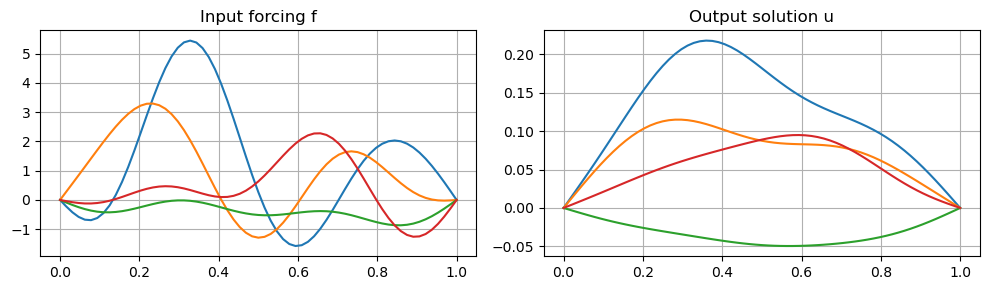

f and u shape: torch.Size([4, 65]) torch.Size([4, 65])


In [2]:
x = torch.linspace(0,1,65)
a = torch.randn(4,5)
f,v = poisson_data(a,x)
u = v/torch.pi**2
fig,ax = plt.subplots(1,2,figsize=(10,3))
ax[0].plot(x,f.T); ax[0].set_title("Input forcing f")
ax[1].plot(x,u.T); ax[1].set_title("Output solution u")
plt.tight_layout(); plt.show()
assert u[:,[0,-1]].abs().max()<1e-6
print("f and u shape:",f.shape,u.shape)

## 2. 中心差分是可检查的参考算法

步长 $h=1/(N-1)$，内部点满足 $(2u_i-u_{i-1}-u_{i+1})/h^2=f_i$。这给出三对角线性系统。我们用稠密求解方便理解，实际大规模 PDE 应使用稀疏算法。

解析解和有限差分解不是完全相同的标签：前者解连续方程，后者解离散方程。先检查网格加密时的误差，才能相信生成的数据。

N=17, relative L2=0.005506
N=33, relative L2=0.001359
N=65, relative L2=0.000339
N=129, relative L2=0.000085


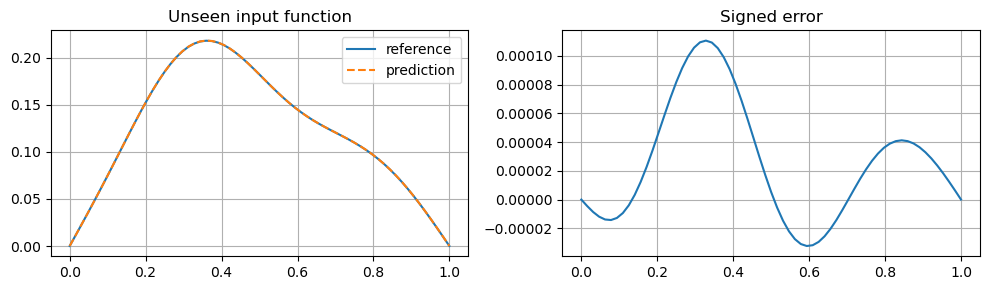

In [3]:
def finite_difference(f):
    n = f.shape[-1]; h = 1/(n-1)
    m = n-2
    A = (2*torch.eye(m,dtype=f.dtype)-torch.diag(torch.ones(m-1,dtype=f.dtype),1)
         -torch.diag(torch.ones(m-1,dtype=f.dtype),-1))/h**2
    interior = torch.linalg.solve(A,f[:,1:-1].T).T
    return torch.nn.functional.pad(interior,(1,1))

errors = []
for n in [17,33,65,129]:
    grid = torch.linspace(0,1,n)
    forcing,scaled = poisson_data(a.double(),grid.double())
    exact = scaled/torch.pi**2
    numerical = finite_difference(forcing.double())
    err = relative_l2(numerical,exact).mean().item()
    errors.append(err); print(f"N={n}, relative L2={err:.6f}")
assert errors[-1]<errors[0]
fd = finite_difference(f)
plot_1d(x,u,fd)

## 3. 怎样评估“学会了解算子”？

训练、验证、测试必须按**整条输入函数**划分。把同一个函数的不同坐标分给训练和测试，只能测插值，不能测新 PDE 泛化。后续章节用不同随机系数生成三个集合，验证集只记录误差，测试集只在训练结束后使用。

相对 $L^2$ 误差是 $\|u_\theta-u\|_2/\|u\|_2$，不同样本先分别计算再平均。接近零解会使它很敏感，故还应观察绝对误差图。坐标图使用英文标注，以兼容未安装中文字体的环境。

**练习：** ① 单独提高最高频系数，观察平滑作用；② 将网格数加倍，检查二阶差分误差约缩小四倍；③ 思考非零边界条件还需要哪些输入信息。

**自检：** 你能解释为什么输入一个标量、预测一个标量的回归与本章的函数映射不同吗？